In [1]:
import os
import sys
import time
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# the notebook can live in lab3/ or lab3/code; always work from lab3/
if os.path.basename(os.getcwd()) == "code":
    os.chdir("..")
sys.path.append("code")  # so we can import our own scripts

from similarity import similarity
from kmeans_stability import load_binary_ling, DATA_PATH
rng = np.random.default_rng(215)  # fixed seed so the subgroups are the same every run

# Introduction

In Lab 2, we found that the dialect survey seemed to split into three main regional groups: the Northeast, the Midwest/Rust Belt, and a more general American group that was strongest in the Southeast. However, choosing the number of clusters was one of the shakiest parts of that analysis. The elbow plot did not have a super clear bend, and the silhouette scores for $k = 3$ and $k = 5$ were almost tied. In this lab, we take a closer look at that question using the stability method from Ben-Hur (2002).

In this method, if a clustering with $k$ groups is capturing real structure in the data, then clustering two different random subsamples should give us almost the same answer for the people who show up in both. If the $k$ number of clusters is too big, k-means is forced to split up a real group, and where it makes that split may change which people--who should be in the same group--happened to land in the subsample. So the two clusterings will disagree. By repeating this many times, we get a whole distribution of similarity scores for each $k$, and the paper suggests picking the largest $k$ where these scores are still bunched up near 1.

For this lab, we use the binary-coded version of the survey data, which has 45,152 respondents and 468 binary columns. Each column is one answer option to one question, which is the same kind of one-hot coding used in Lab 2. We set the maximum number of clusters to $k_{max} = 10$, the number of repeats to $B = 100$, and the sampling fraction to $m = 0.8$, which is the largest value allowed.

This takes heavy computation. First, with $m = 0.8$ the two subsamples share about 29,000 people, and the most obvious way to compare two clusterings would need a $29{,}000 \times 29{,}000$ matrix that takes up about 6 GB. Second, the whole procedure needs 1,800 k-means fits on about 36,000 people each. In the next section we describe a similarity function that gets around the giant matrix and runs in time that grows linearly with the number of people. Then we describe how we ran Algorithm 1 in parallel on the SCF cluster, and finally we look at the results and what they say about the right number of clusters.

# Similarity Implementation

## Choice of similarity measure

We chose the **Jaccard coefficient** as our similarity measure. For any two people and two different clusterings, they can be grouped together both times, grouped together only once, or kept apart both times. The Jaccard coefficient looks at every pair that was grouped together at least once, and asks what fraction of those pairs were grouped together both times:
$$J = \frac{N_{11}}{N_{01} + N_{10} + N_{11}} = \frac{\text{pairs together in both clusterings}}{\text{pairs together in at least one clustering}}.$$
If the two clusterings are exactly the same, the Jaccard similarity score is 1. The more they disagree, the closer the score gets to 0.

TThe Ben-Hur paper lists three methods for measuring similarity: correlation, matching, and Jaccard. We chose Jaccard primarily due to an issue with matching. Matching also includes pairs that were placed in different clusters in both runs, and since our data has most pairs being placed in different clusters regardless of the clustering, most pairs (such as a respondent in Boston, MA and a respondent in Atlanta, GA) are in different clusters in both runs regardless of whether the clustering is stable. Even at $k = 3$, roughly two thirds of pairs are apart in any clustering. These easy pairs would make up most of the matching score. Jaccard ignores them and only looks at the pairs where something interesting happened. The paper also says Jaccard and correlation behave very similarly in practice, so we are not losing much by picking Jaccard over correlation.

## Algorithm

We do not have to check all pairs of individuals. To compute the Jaccard index, we just need to know three numbers: the number of pairs of individuals that were assigned to the same cluster in both clusterings ($N_{11}$); the number of pairs of individuals that were assigned to the same cluster in the first clustering; and the number of pairs of individuals that were assigned to the same cluster in the second clustering. All three of these numbers are determined solely by the number of individuals assigned to each possible combination of clusters, and not by which specific individuals are assigned to which combination of clusters.

Therefore, rather than checking all pairs, we create a small table. Each row represents a cluster from the first clustering; each column represents a cluster from the second clustering; and each cell represents the number of individuals who were assigned to both clusters. Since $k=10$, this table will have only 100 cells. For any group of $n$ individuals, there are $\binom{n}{2}=n(n-1)/2$ possible pairs. Two individuals are assigned to the same cluster in both clusterings if and only if they are assigned to the same cell in this table.

Therefore, by summing the pairs within each cell, we obtain the "together in both" count. Similarly, since the row totals represent the cluster sizes from the first clustering, by summing the pairs within each row, we obtain the "together in the first" count, and by summing the pairs within each column, we obtain the "together in the second" count.

The algorithm goes through the people once to fill in the table, and then adds. The runtime is $O(q + k_1 k_2)$, where $q$ is the number of shared people and $k_1$ and $k_2$ are the numbers of clusters. Since $k$ is at most 10, this grows in a straight line with $q$. Because we only store the small table, we never need the very large $q \times q$ matrix. For comparison, checking every pair one by one is $O(q^2)$ (from the $q \times q$ matrix).

## Python implementation

The loop over all people is slow in plain Python, so we compiled the whole calculation (filling the table and adding up the pairs) with Numba's @njit.

On benchmark.py, our function took 1.8262863159179686e-05 seconds (18.3µs) for $q = 5{,}000$ and 5.0687789916992186e-05 (50.7µs) seconds for $q = 29{,}000$. For comparison, the reference smart implementation takes 58 µs and the reference $O(q^2)$ version takes 0.32 s at $q = 29{,}000$.


## Timing on lingBinary for different values of $m$

For each $m$ from 0.2 to 0.8, we drew two subsamples of lingBinary, ran k-means with $k = 10$ on each, and timed similarity function on the shared people, averaged over 1,000 calls. We call the function once before timing so that Numba's one-time compile step isn't counted.

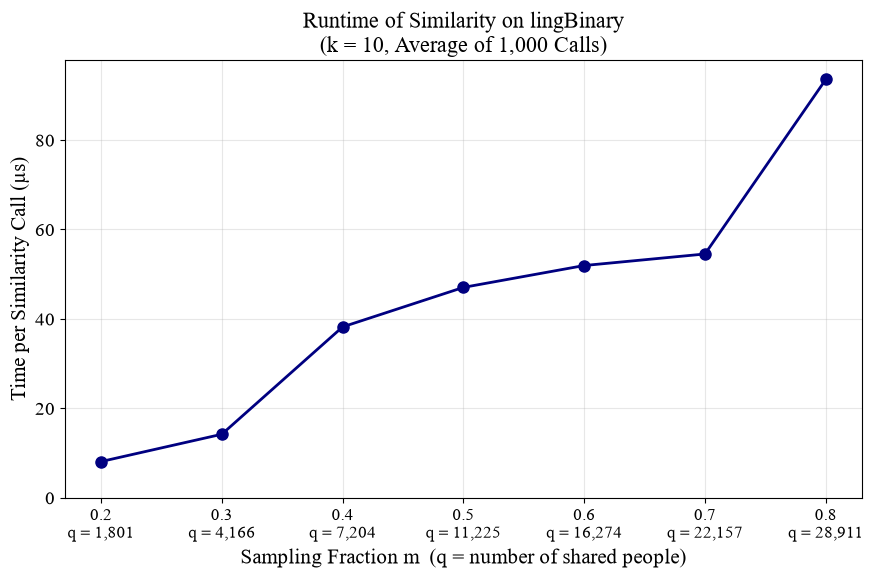

In [4]:
# load the data (binary columns only)
data = load_binary_ling(DATA_PATH)

# call similarity once first, so Numba compiles it now
# (otherwise the compile time would get counted in the first timing)
similarity(np.array([0, 1]), np.array([0, 1]))

m_values = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]  # the sampling fractions to try
q_values = []      # how many shared people each m gives
times_us = []      # how long similarity took for each m, in microseconds
n_people = data.shape[0] # Number of people in data

for m in m_values:
    # two subgroups of this size, picked separately
    n_sub = int(round(m * n_people))
    sub1 = np.sort(rng.choice(n_people, size=n_sub, replace=False))
    sub2 = np.sort(rng.choice(n_people, size=n_sub, replace=False))

    # k-means with k = 10 on each subgroup (k = 10 matches the instructor's benchmark)
    labels1 = KMeans(n_clusters=10, n_init=1, random_state=1).fit_predict(data[sub1])
    labels2 = KMeans(n_clusters=10, n_init=1, random_state=2).fit_predict(data[sub2])

    # the shared people, and their two membership vectors
    _, pos1, pos2 = np.intersect1d(sub1, sub2, assume_unique=True, return_indices=True)
    membership1 = labels1[pos1]
    membership2 = labels2[pos2]

    # time similarity: one call is too fast to measure, so run it 1,000 times and divide
    start = time.perf_counter()
    for _ in range(1000):
        similarity(membership1, membership2)
    seconds_per_call = (time.perf_counter() - start) / 1000

    q_values.append(len(membership1))
    times_us.append(seconds_per_call * 1e6)  # 1e6 turns seconds into microseconds
    #print(f"m = {m}: q = {len(membership1):6,} shared people, {seconds_per_call * 1e6:.1f} µs per call")

# ---------- Plot ----------
plt.rcParams.update({
    "font.size": 14,
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "mathtext.fontset": "stix",   # Times-like font for any math text
})

plt.rcParams.update({"font.size": 14})

fig, ax = plt.subplots(figsize=(9, 6))
ax.plot(m_values, times_us, "o-", color="navy", markersize=8, linewidth=2)

# x-axis ticks: m on the first line, q (shared people) on the second
ax.set_xticks(m_values)
ax.set_xticklabels([f"{m}\nq = {q:,}" for m, q in zip(m_values, q_values)],
                   fontsize=12)

ax.set_xlabel("Sampling Fraction m  (q = number of shared people)", fontsize=15)
ax.set_ylabel("Time per Similarity Call (µs)", fontsize=15)
ax.set_title("Runtime of Similarity on lingBinary\n(k = 10, Average of 1,000 Calls)",
             fontsize=16)
ax.set_ylim(bottom=0)
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("C:/Users/jcoll/Desktop/Everything/2026 Berkeley Fall/STAT 215A/stat-215a/lab3/figs/time_per_similarity_call.png", dpi=300, bbox_inches="tight")
plt.show()

<div align="center">

 Figure 1: Time per Call for each Subsample Fraction (q), shows algorithmic fit to O(q) 

</div>


The number of shared people grows from about 1,800 at $m = 0.2$ to about 28,800 at $m = 0.8$. The runtime grows with $q$, from about 20 µs to about 85 µs, which fits the $O(q)$ algorithm. This fits the $O(q)$ algorithm, since an $O(q^2)$ method would have been computationally more expensive and slower. Even the slowest call is far under the 1 ms target, so almost all of Algorithm 1's runtime comes from k-means, not the similarity function.

# Algorithm 1 Implementation

We used kmeans_stability.py to implement Algorithm 1 and ran it on the SCF using the job script run.sh with sbatch. For each $k$ from $k=2$ to $k=10$ and each of the 100 repeats, the script drew two subsamples of 80% of the respondents, ran k-means on each, found the respondents who were in both, and computed the Jaccard similarity of their two sets of labels. The results were saved in results/S.csv, with one row per repeat and one column per $k$.

## Choice of k-means parameters

We used the k-means implementation from scikit-learn. Scikit-learn has several ways to select the initial centers. We maintained the default k-means++ setting, which spreads out the initial points; we believe this produces better solutions than randomly selecting them, where initial centers may start in the same cluster. We set the number of restarts to n_init=1. We did this to minimize the time required to execute Algorithm 1 and to monitor/evaluate how consistent the clustering procedure is. If we ran k-means multiple times and only selected the best run, we would be obscuring some of the instability that arises from where k-means begins. Additionally, one restart minimized the time required to perform one k-means fit per subsample, which was important because we needed 1,800 of them. We maintained the default stopping rule of at most 300 iterations.

The k-means method employs squared Euclidean distance, and on 0/1 data this is precisely the number of answer options where two individuals differ, which is an appropriate method for measuring how different two individuals' answers are. Finally, each $(k, i)$ pass receives its own random seed, $215 + 2(kB + i - 1)$. That seed is used for drawing the subsamples, which we want to be different! The two k-means fits use that seed and the seed plus one. Therefore, anyone can rerun the script and obtain the exact same S.csv.

## Parallelization

The 900 total passes (9 values of k x 100 repeats per value) are all totally independent of each other; the only thing they have in common is the data, and none of them modify it.

Therefore, rather than deciding whether to parallelize the inner or outer loop, we created a single list of 900 tasks (one for each combination of k and repeat) and distributed these tasks among the available cores via joblib. We chose not to parallelize only the outer loop because doing so would result in only 9 large tasks (one for each value of k), each consisting of all 100 repeats. Since there are so few tasks, the cores cannot effectively distribute the workload. If the number of cores does not happen to be divisible by 9, some cores will be assigned an additional task to complete independently while other cores remain idle. Additionally, the time required to complete each task varies significantly based upon the value of k. Based on k-means took approximately three times longer at k=10 than at k=2.

Therefore, cores that finish a smaller value of k quickly will also remain idle.

While parallelizing only the inner loop would ensure that the cores remain active within each value of k, all workers would need to wait for each other to complete before proceeding to the next value of k. By creating a single list of 900 small tasks, each core simply retrieves the next task as soon as it completes a task, thereby ensuring that all cores remain active until all outcomes are completed.

One detail we would not have caught on our own came from Claude, which pointed out that k-means in scikit-learn already tries to use all of the computer's cores at once. Since joblib is also running many k-means fits side by side, each one trying to grab every core would leave the cores overloaded and slow everything down. Following Claude's suggestion, we told joblib to limit each k-means fit to a single core (inner_max_num_threads=1). That way, each core works on one k-means fit at a time, and all of the parallel work comes from joblib running many fits at once.

## Runtime and cores

We asked the SCF for 8 cores.  We did this becuase it was the default that SCF gave. Since there are 900 independent tasks, more cores directly cut the runtime, and 8 is a request that the SCF can usually fill without a long wait in the queue.

The job took 958.7 seconds (about 16 minutes) to run. Asking the AI about runtimes, we found that this works out to roughly 7,700 core-seconds, or about 4.3 seconds per k-means fit, so running all 1,800 fits on a single core would take a little over 2 hours.

# Result

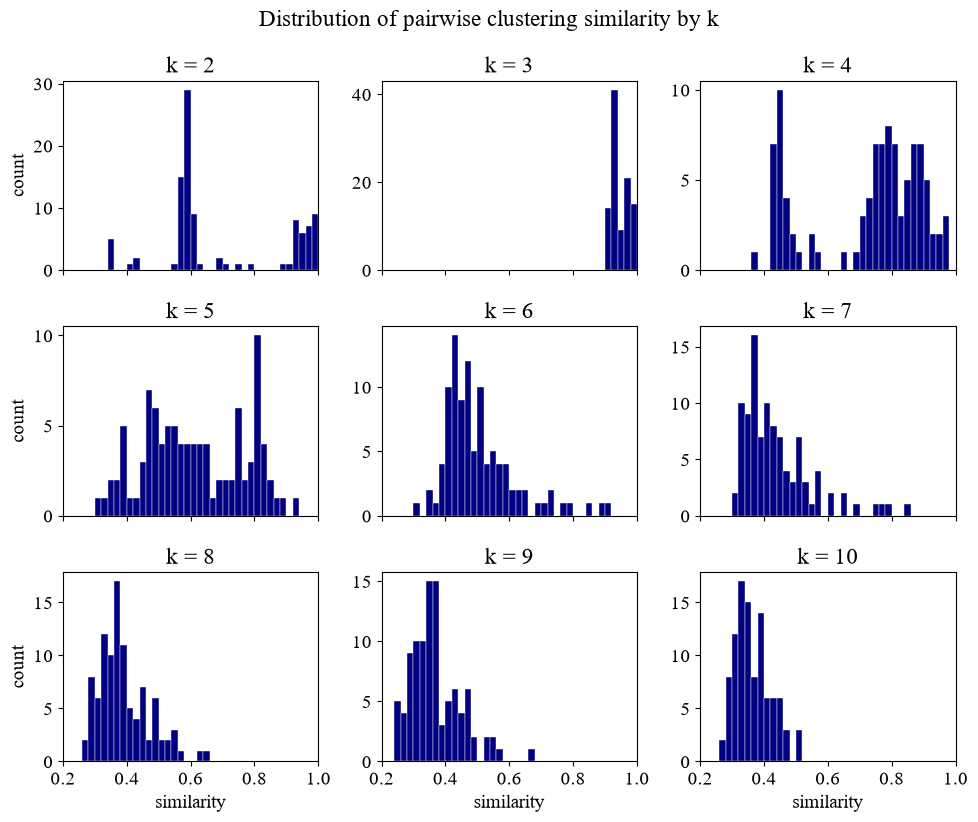

In [5]:
S = pd.read_csv("results/S.csv", index_col=0)

# Map each column name ("k2", "k=2", "2", ...) to its integer k, sorted by k
ks = {col: int(re.search(r"\d+", str(col)).group()) for col in S.columns}
cols = sorted(S.columns, key=ks.get)
 
# Histogram of Similarities for each k
n = len(cols)
ncol = 3
nrow = int(np.ceil(n / ncol))
lo = np.floor(S.min().min() * 20) / 20   # round down to nearest 0.05
bins = np.linspace(lo, 1, 41)
 
fig, axes = plt.subplots(nrow, ncol, figsize=(10, 2.8 * nrow), sharex=True)
for ax, col in zip(axes.flat, cols):
    ax.hist(S[col], bins=bins, color="navy", edgecolor="white", linewidth=0.3)
    ax.set_title(f"k = {ks[col]}")
    ax.set_xlim(lo, 1)
for ax in axes.flat[n:]: # hide unused panels
    ax.axis("off")
for ax in axes[-1]:
    ax.set_xlabel("similarity")
for ax in axes[:, 0]:
    ax.set_ylabel("count")
fig.suptitle("Distribution of pairwise clustering similarity by k")
fig.tight_layout()
fig.savefig("C:/Users/jcoll/Desktop/Everything/2026 Berkeley Fall/STAT 215A/stat-215a/lab3/figs/similarity_histograms.png", dpi=300, bbox_inches="tight")
plt.show()


<div align="center">

 Figure 2: Histogram of Jaccard Similarity Scores per Number of Clusters (k)

</div>




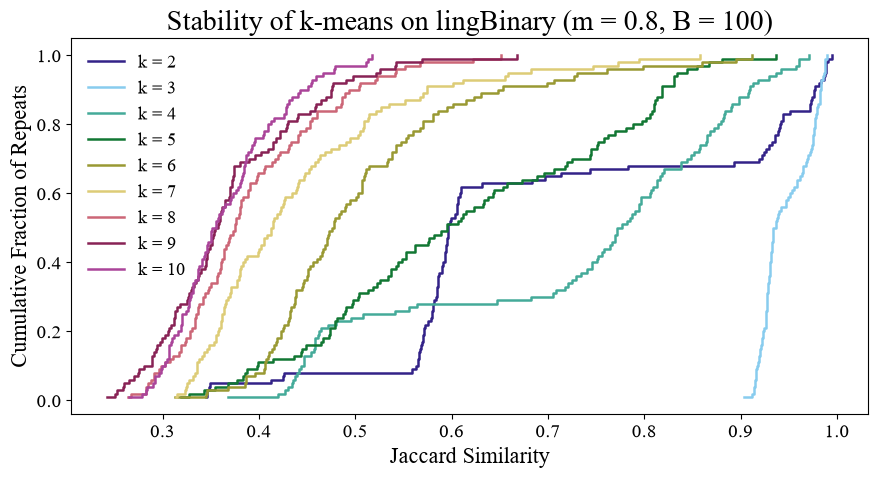

In [6]:
#Stability of K-means on Lingdata
fig, ax = plt.subplots(figsize=(9,5))
# Paul Tol's "muted" palette: 9 colors that stay distinct for color-blind readers
colors = ["#332288", "#88CCEE", "#44AA99", "#117733", "#999933",
          "#DDCC77", "#CC6677", "#882255", "#AA4499"]


for idx, (color, col) in enumerate(zip(colors, S.columns)):
    # sort the similarities and step up 1/B at each one: the cumulative distribution
    values = np.sort(S[col].to_numpy())
    ax.step(values, np.arange(1, len(values) + 1) / len(values), where="post",
            color=color, lw=1.8,
            label=f"k = {col}")
ax.set_xlabel("Jaccard Similarity", fontsize = 16)
ax.set_ylabel("Cumulative Fraction of Repeats", fontsize = 16)
ax.set_title(f"Stability of k-means on lingBinary (m = 0.8, B = {len(S)})", fontsize = 20)
ax.legend(fontsize=13, frameon=False)
plt.tight_layout()
fig.savefig("C:/Users/jcoll/Desktop/Everything/2026 Berkeley Fall/STAT 215A/stat-215a/lab3/figs/stability_of_kmeans.png", dpi=300, bbox_inches="tight")
plt.show()

<div align="center">

 Figure 3: Stability of k-means Using Jaccard Similarity Measure Across 100 Iterations per Cluster Amount (k)
</div>


## Discussion of the Plot

Figure 2 shows the distribution of similarity scores for 100 iterations of each $k$ value. Figure 3 show the cumulative distribution of the 100 similarity scores for each $k$. Inspiration for these graphs were taken from Figure 3 in  Ben-Hur et al. A stable and optimal $k$ shows consistent Jaccard similarity values near 1. We can see from Figures 2 and 3 that $k = 3$ clearly has the highest stability. The Jaccard scores are tightly bunched around 1 and, as in Figure 3, the curve remains far to the right. This indicates that for almost every iteration, the Jaccard Similarity score was close to 1 and the k-means split the respondents into the same 3 groups.

It was interesting that $k=2$ and $k=4$ also had high Jaccard scores, but were very unstable. It was particularly curious to see that some of $k=2$ runs outperformed the $k=3$ runs with a higher Jaccard similarity score, but its instability led it to have a worse overall outcome. Ben-Hur et al. describes that when the data has several groups and there isn't one obvious way to merge them into two, the algorithm switches between different two-cluster answers. Since we have found that $k=3$ really is the best outcome, different choices are make when k-means is forced to use only two.

After $k = 3$, the stability drops off quickly. At $k = 4$ the scores move to the left (get smaller) and spread out, which suggests k-means doesn't have a consistent way to split one of the three groups into two. From about $k = 7$ to $k = 10$, the scores all sit at a low level and follow a similar shape as in Ben Hur's paper Figure 7. 

## Choice of $k$

We would pick **$k = 3$**. It is the largest $k$ whose scores are still bunched up near 1, which is the Jaccard rule described in the Ben Hur paper. There is no other $k$ value that rivals it.

This lines up with Lab 2, where k-means with $k = 3$ split the respondents into the Northeast, the Midwest/Rust Belt, and a general American group that was strongest in the Southeast. In Lab 2 the case for $k = 3$ was weak: the elbow plot didn't have a clear bend, and the silhouette score for $k = 3$ (0.142) barely beat $k = 5$ (0.141). This stability method gives a much clearer answer.

## Do I trust this method?

We would mostly trust the method, but there are many details within the code that make it perhaps reliable in this case but not as much in others.

First, clustering is, as stated in class, a human method. We are assuming that there are clusters and are therefore going through this process. We are trying to see if there are different dialects in the United States, but as time goes on and the connectedness of the world increases, perhaps dialects will be less distinct. In that case, would it be possible to cluster? We are assuming that the clusters reflect real-life, distinct groups. Technically, k-means will split a long stretched-out cloud of points the same way every time, even if there are no real clusters in it.

Second, beyond just clustering itself, our ultimate clustered results depend on the algorithm and its settings. What we measured is the stability of k-means with k-means++ and one restart. It is possible that there would be differences if we did not use k-means++ to randomize the starting centroids and with more restarts, every $k$ may look more stable. 

Third, the subsamples overlap a lot. With the share of people going into each subsample $m = 0.8$, the two subsamples share a lot of the data, so the two k-means runs see very similar data and will tend to agree even if the structure is weak. A smaller $m$ would be a tougher test since the two runs would need to see the *same* groups from *different* individuals.

Overall, the method works well beucase it works with any clustering algorithm and directly tests something we want from any useful clustering: that it doesn't depend on exactly which respondents are included in the data. Here, the answer is clear and matches Lab 2, which makes us more confident in $k = 3$.

## Other ways to choose $k$

Another way to choose $k$ is to scramble the columns/questions and randomly sample those to form the clusters. If about 80% of the quesitons are taken each iterations, and then we look for clusters based on those, we can see if our k clusters hold for a different variety of questions each time. This would add to our confidence in our $k$ clusters where all questions are used if the same clusters can appear within a subsample of the questions.

# Academic Honesty

## Statement

Professor Bin, For these assignments, I will maintain academic integrity and cite all sources that are used including collaborations and LLM use. Academic research honesty is necessary for the ultimate trustworthiness of future scientific knowledge. Being open about assumptions made and how conclusions were drawn can ensure that generalizations are minimized and the statistics can stay as objective as possible. In a world where it can be easy to skew the statistics to support a particular point of view, research performed with integrity can help minimize the misinterpretation of the data. Further, if science was made to understand life's complexities, then it is imperative that assumptions be observed, listed and challenged. Then, we can have a more robust foundation to build future research that can withstand the test of time. We can celebrate inquiry, notice where we fail, and not let that deter us from the pursuit of something a bit greater. Being honest about research means renouncing a fear of failure, being humble about findings, honoring the scientific method, and working toward the betterment of oneself as a scientist and the broader scientific community.

## LLM Usage

### Writinig and Coding

I used Claude's Opus 5.5 for the coding in this lab.  Claude helped me build the template notebook step by step. I asked for particular with code efficiency. Specifically, helping in the parallelization phase and how to time the process. Once I had the fundamentals for the similarity.py and kmeans_stability, it help me compile them into .py files. I also used it for debugging (for example, a Numba compile error and a variable-name error).

LLM Conversation link: https://claude.ai/share/3986e8ca-b394-45c2-83d7-50e623b9edef

### Experience

Claude does help me save time when coding. With a busy scheule, it does help me grasp the main ideas without having to worry about learning computer science in such detail. Becuase I am unfamiliar with SCF, I asked it to help with that process as well and the powershell commands that would help me through that process. I also asked it many questions on how to code and make things more efficient. Usually, I have it explain code to me as simply as possible. I check the code and ensure I can follow its process, and check to see if any steps hold hidden assumptions. However, having a baseline of code to use is very helpful when I am trying to get things done quickly. Of course, I do not think my coding skills are getting particularly stronger by using AI, but I am more focused on learning the larger aspects of the class.

## Collaborators

None.

# Bibliography

Ben-Hur, A., Elisseeff, A., & Guyon, I. (2002). A stability based method for discovering structure in clustered data. *Pacific Symposium on Biocomputing*, 7, 6–17.